# Do induction heads exist in GPT-2, and does removing them actually hurt the model’s ability to do in-context learning?

## Introduction
Transformer-based language models can learn from patterns provided by inputs, without the need to update their parameters. This is known as in-context learning (ICL). This internal mechanism remains an active area of research.

One proposed explanation is the existence of induction heads. These are attention heads that allow the model to recognise repeated token sequences in order to predict what comes next. A simple example could be the input "A B A B A B A", a model with an effective induction mechanism will assume the next token to be B.

The influential 2022 paper "In-context Learning and Induction Heads" by Olsson et al. presents evidence that induction heads aid greatly in the pattern recognition behaviour. This paper was my main source and inspiration for this project.

This project aims to investigate these claims in GPT2, using mechanistic interpretability to examine the behaviour and causal importance of its attention heads. It also aims to reproduce key findings from existing mechanistic interpretability research while testing the causal contribution of induction heads in GPT2. Rather than assuming they are necessary for ICL, it treats their importance as an empirical question to be investigated through controlled experiments.

The final results will help to distinguish the model's ability to recognise repeated token patterns and its broader ability to learn from examples in context.

In [36]:
from transformer_lens.model_bridge import TransformerBridge
import torch
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random

model = TransformerBridge.boot_transformers("gpt2", device="cpu")

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [37]:
# some model configs for reference
print(model.cfg.n_layers, model.cfg.n_heads, model.cfg.d_vocab)

12 12 50257


In [38]:
prompt = "The cat sat on the mat. The dog sat on the rug. The cat sat on the"

tokens = model.to_tokens(prompt)
logits = model(tokens)

# Look at the prediction for the very last token position
final_logits = logits[0, -1, :]
predicted_token_id = final_logits.argmax().item()
predicted_token = model.to_string(predicted_token_id)

print(f"Model predicts next token: '{predicted_token}'")

Model predicts next token: ' floor'


The model said “ floor” even though “mat” and “rug” both appeared earlier in the prompt. “Sat on the floor” is such a common phrase that GPT-2’s prior beat the in-context cue. This doesn’t mean induction heads don’t exist. It means a natural sentence can’t separate “copying from context” from “knowing English,” and a single repetition is a weak signal anyway.

Random tokens fix both problems. A random sequence has no language prior, so the only way to predict the second copy is to look back at the first.

In [39]:
seq_len = 50
batch = 10
torch.manual_seed(0) #allows runs to be reproducible

# Random tokens (skipping the lowest ids, which are mostly punctuation/special)
rand_tokens = torch.randint(1000, model.cfg.d_vocab, (batch, seq_len))
bos = torch.full((batch, 1), model.tokenizer.bos_token_id)
tokens = torch.cat([bos, rand_tokens, rand_tokens], dim=1)  # [BOS, X, X]

with torch.no_grad():
    logits = model(tokens)

log_probs = logits.log_softmax(-1)
# Log-prob the model assigned to each actual next token
correct_log_probs = log_probs[:, :-1].gather(-1, tokens[:, 1:].unsqueeze(-1)).squeeze(-1)

first_copy_loss  = -correct_log_probs[:, :seq_len].mean().item()
second_copy_loss = -correct_log_probs[:, seq_len + 1:].mean().item()

print(f"Loss on first copy:  {first_copy_loss:.3f}")
print(f"Loss on second copy: {second_copy_loss:.3f}")

Loss on first copy:  13.119
Loss on second copy: 0.183


By making 10 random sequences of 50 tokens each, the model cannot lean on English, therefore it has to predict the second round by remembering the first.

Since the model predicts the next token at each position, predictions from positions 0 to 99 are compared with the actual tokens from positions 1 to 100. "gather" picks out the log-probability the model gave to the correct token. This is why "[:, :-1]" and "[:, 1:]" are offset by one.

A higher loss on the first copy is to be expected as the model has no way to predict random tokens. A model guessing uniformly across 50257 tokens (d_vocab value) would score around 10.8, the loss is higher as GPT-2 favours likely words, thus random tokens would surprise it even more.

The second-copy loss skips the first token of the second copy. That token follows the last token of the first copy, which has never appeared before, so nothing in the context can predict it. Including it would add about 0.26 to the average and hide the true size of the copying effect. With the skipped token excluded, the loss is 0.18.

The second copy's loss means the model was almost never surprised at all. So far we can conclude it must be looking at the first copy and reproducing it. This is the in-context behaviour induction heads are thought to implement. This establishes that repeated context provides a predictive advantage.

#### However, this itself does not prove that induction heads are fully responsible. 

## Identifying Candidate Induction Heads

The next step is to investigate which attention heads may be responsible for this behaviour.

An induction head is expected to use information from an earlier occurrence of a token sequence to help predict its continuation. In a repeated sequence, this may produce a distinctive attention pattern: when processing the second occurrence, a head attends to a position in the first occurrence that provides information about the next token.

To investigate this, I will cache the model's attention patterns and examine how individual heads distribute their attention across the input. In particular, I will look for heads that attend from the second copy to relevant positions in the first copy.

Attention patterns provide a way to identify candidate induction heads, but attention alone does not establish causal importance. The following experiments will therefore use targeted ablations to test whether these heads contribute to the observed repetition benefit.

In [40]:
# `tokens` should contain the repeated-token sequences: [BOS, X, X]
logits, cache = model.run_with_cache(tokens)

print("Number of layers:", model.cfg.n_layers)
print("Attention heads per layer:", model.cfg.n_heads)

# Inspect the attention pattern in layer 5
layer = 5
pattern = cache[f"blocks.{layer}.attn.hook_pattern"]

print(f"Attention pattern shape in layer {layer}:", pattern.shape)

Number of layers: 12
Attention heads per layer: 12
Attention pattern shape in layer 5: torch.Size([10, 12, 101, 101])


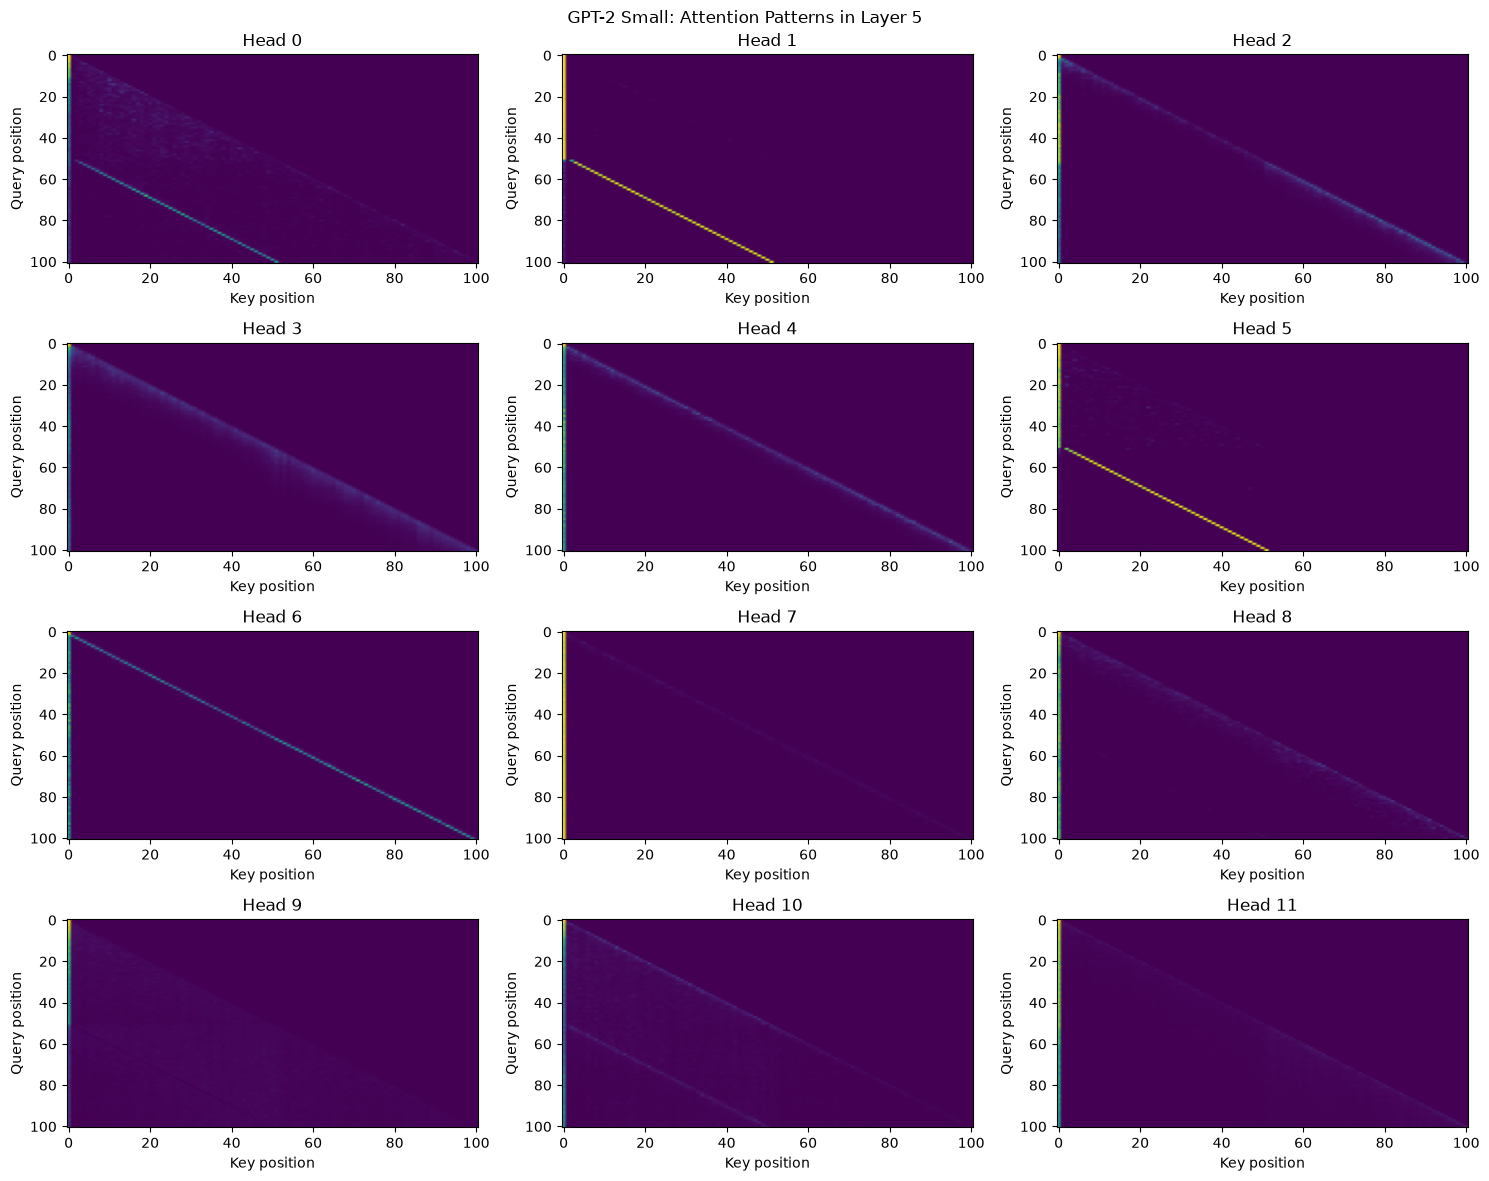

In [41]:
# Average attention patterns over the batch
layer_patterns = pattern.mean(dim=0).detach().cpu()

n_heads = model.cfg.n_heads
fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for head, ax in enumerate(axes.flat):
    ax.imshow(layer_patterns[head].numpy(), aspect="auto")
    ax.set_title(f"Head {head}")
    ax.set_xlabel("Key position")
    ax.set_ylabel("Query position")

plt.suptitle(f"GPT-2 Small: Attention Patterns in Layer {layer}")
plt.tight_layout()
plt.show()

Some heads show a diagonal on or just below the main diagonal. These attend to the previous token and are known as previous-token heads. An induction head should instead show a diagonal in the bottom-left block (query positions 51 to 100, key positions 1 to 50), shifted about 49 positions back from the main diagonal, because each token in the second copy should attend to the token after its earlier occurrence.

These heatmaps provide an initial visualisation of attention, the next step is to investigate the positional relationships more directly.

In [42]:
# Inspect the first repeated-token sequence
sequence = tokens[0].detach().cpu()

print("Token IDs:")
print(sequence.tolist())

print("\nDecoded sequence:")
print(model.to_string(sequence))

Token IDs:
[50256, 41823, 7138, 49413, 40705, 49814, 31723, 7100, 9371, 30917, 34336, 39375, 10254, 22921, 28048, 11072, 5511, 32374, 14950, 11256, 2983, 26388, 6150, 2322, 32547, 34614, 45105, 23570, 47412, 49948, 14797, 13052, 20143, 47529, 42604, 17795, 11122, 22115, 45090, 38691, 16469, 34968, 14971, 34622, 23894, 36605, 4326, 15377, 47537, 47598, 31076, 41823, 7138, 49413, 40705, 49814, 31723, 7100, 9371, 30917, 34336, 39375, 10254, 22921, 28048, 11072, 5511, 32374, 14950, 11256, 2983, 26388, 6150, 2322, 32547, 34614, 45105, 23570, 47412, 49948, 14797, 13052, 20143, 47529, 42604, 17795, 11122, 22115, 45090, 38691, 16469, 34968, 14971, 34622, 23894, 36605, 4326, 15377, 47537, 47598, 31076]

Decoded sequence:
<|endoftext|>alos perfectly nihil cryptographic 383 politictle Atlanta Ibrahim Houses PocatalMAX Doesnchi Bushlimit———————— Huiclesoslav remained vol Ninth catalogue pulmonaryettle Barron bounded Charg suggestion deserved Mesh portals linkingSl reservoir Powered cardinalspring 

To visualise this more the repeated token sequence is shown above. For a token at position i its copy is located at position i+50 (as a sequence with length 50 was generated). A token at position i+50 is therefore the repeat of position i.

An induction head there should attend to position i+1, the token that followed the first occurrence. I quantify this by measuring the attention weight on those expected positions for every head. Heads that consistently score high are candidates for further investigation.

In [43]:
# Query positions: tokens in the second copy, excluding its final token
query_positions = torch.arange(seq_len + 1, 2 * seq_len)

# Expected key positions: the tokens that followed the matching
# occurrences in the first copy
key_positions = query_positions - seq_len + 1

scores = []

for layer in range(model.cfg.n_layers):
    pattern = cache[f"blocks.{layer}.attn.hook_pattern"]

    # Shape after indexing: [batch, heads, positions]
    expected_attention = pattern[
        :, :, query_positions, key_positions
    ]

    # Average across sequences and query positions
    head_scores = expected_attention.mean(dim=(0, 2))

    for head in range(model.cfg.n_heads):
        scores.append({
            "layer": layer,
            "head": head,
            "induction_score": head_scores[head].item()
        })

scores_df = pd.DataFrame(scores)

# Display the 10 heads with the highest scores
scores_df.sort_values(
    "induction_score", ascending=False
).head(10).reset_index(drop=True)

,layer,head,induction_score
0,5,5,0.939574
1,5,1,0.918326
2,6,9,0.916927
3,7,10,0.916696
4,7,2,0.832519
5,10,1,0.532414
6,9,6,0.518627
7,9,9,0.506095
8,10,7,0.462389
9,5,0,0.443685


The top five heads all score above 0.83, then there is a clear drop to 0.53. These match the induction heads usually reported for GPT-2 small, so this reproduces a known result. I define an “induction head” here as any head scoring above 0.8. This is a cutoff based on the gap, not a sharp boundary.

In [53]:
THRESHOLD = 0.8

induction_heads = []
for _, row in scores_df.iterrows():
    if row["induction_score"] > THRESHOLD:
        induction_heads.append((int(row["layer"]), int(row["head"])))

print(induction_heads)

[(5, 1), (5, 5), (6, 9), (7, 2), (7, 10)]


## Causal test: ablating the induction heads

Attention patterns are correlational. To test whether these heads are causally responsible for the repetition benefit, I ablate them and measure the change in loss. If the second-copy loss rises substantially while the first-copy loss barely moves, the heads contribute to copying. I use mean ablation (replacing a head’s output with its average output over a reference batch) rather than zero ablation, because zeros are an input the model never sees naturally and could exaggerate the damage.

In [45]:
def repeated_loss(tokens, fwd_hooks=[]):
    with torch.no_grad():
        logits = model.run_with_hooks(tokens, fwd_hooks=fwd_hooks)
    log_probs = logits.log_softmax(-1)
    correct = log_probs[:, :-1].gather(-1, tokens[:, 1:].unsqueeze(-1)).squeeze(-1)
    first  = -correct[:, :seq_len].mean().item()
    second = -correct[:, seq_len + 1:].mean().item()
    return first, second

baseline = repeated_loss(tokens)
print("Baseline (first copy, second copy):", baseline)

Baseline (first copy, second copy): (13.118559837341309, 0.18348948657512665)


In [46]:
n_layers, n_heads = model.cfg.n_layers, model.cfg.n_heads

def compute_means(token_batch):
    with torch.no_grad():
        _, c = model.run_with_cache(
            token_batch, names_filter=lambda n: n.endswith("hook_z")
        )
    return {l: c[f"blocks.{l}.attn.hook_z"].mean(dim=(0, 1)) for l in range(n_layers)}

# Reference batch, separate from the evaluation batch
ref_rand = torch.randint(1000, model.cfg.d_vocab, (50, seq_len))
ref_bos  = torch.full((50, 1), model.tokenizer.bos_token_id)
ref_tokens = torch.cat([ref_bos, ref_rand, ref_rand], dim=1)
mean_z = compute_means(ref_tokens)

def make_hooks(heads, means=None):
    means = mean_z if means is None else means
    by_layer = {}
    for l, h in heads:
        by_layer.setdefault(l, []).append(h)
    hooks = []
    for l, hs in by_layer.items():
        def hook_fn(z, hook, hs=hs, l=l):
            z[:, :, hs, :] = means[l][hs]
            return z
        hooks.append((f"blocks.{l}.attn.hook_z", hook_fn))
    return hooks

Before trusting the main result I run two checks. With no heads ablated, the loss must match the baseline exactly (the hook code does nothing by itself). With every head ablated, the model should break on both copies (the hooks actually change behaviour).

In [47]:
print("No-op hooks:", repeated_loss(tokens, make_hooks([])), "vs baseline", baseline)

all_h = [(l, h) for l in range(n_layers) for h in range(n_heads)]
print("All heads ablated:", repeated_loss(tokens, make_hooks(all_h)))

No-op hooks: (13.118559837341309, 0.18348948657512665) vs baseline (13.118559837341309, 0.18348948657512665)
All heads ablated: (12.504318237304688, 12.689081192016602)


In [48]:
ablated = repeated_loss(tokens, make_hooks(induction_heads))
print("Baseline:           ", baseline)
print("Induction ablated:  ", ablated)

Baseline:            (13.118559837341309, 0.18348948657512665)
Induction ablated:   (12.967306137084961, 5.5711565017700195)


Ablating the five induction heads raised the second-copy loss from 0.18 to 5.57, while the first-copy loss was essentially unchanged (13.12 → 12.97). This removes roughly 43% of the repetition benefit (12.94 → 7.40 nats), which suggests these heads are causally important for copying repeated context, but not solely responsible: the model retains most of its ability to predict the second copy better than chance. Possible explanations include weaker induction heads below my threshold and redundant mechanisms, tested below.

Baseline:          0.183
Induction ablated: 5.571
Random 5 ablated:  0.294 ± 0.221


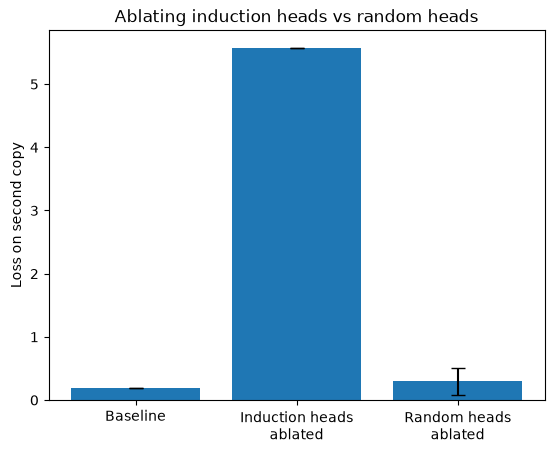

In [50]:
random.seed(0)
non_induction = [(l, h) for l in range(n_layers) for h in range(n_heads)
                 if (l, h) not in induction_heads]

control_second = []
for _ in range(20):
    sample = random.sample(non_induction, len(induction_heads))
    control_second.append(repeated_loss(tokens, make_hooks(sample))[1])

print(f"Baseline:          {baseline[1]:.3f}")
print(f"Induction ablated: {ablated[1]:.3f}")
print(f"Random 5 ablated:  {np.mean(control_second):.3f} ± {np.std(control_second):.3f}")

plt.bar(["Baseline", "Induction heads\nablated", "Random heads\nablated"],
        [baseline[1], ablated[1], np.mean(control_second)],
        yerr=[0, 0, np.std(control_second)], capsize=5)
plt.ylabel("Loss on second copy")
plt.title("Ablating induction heads vs random heads")
plt.show()

Ablating five randomly chosen non-induction heads raised the second-copy loss only to 0.29 ± 0.22 (20 draws), compared with 5.57 for the induction heads. The effect is therefore specific to these heads and not a general consequence of removing five heads. One limitation: the random heads are drawn from all layers, so a layer-matched control would be stricter.

Each head alone:
(5, 1) 0.859
(5, 5) 0.218
(6, 9) 0.214
(7, 2) 0.205
(7, 10) 0.181


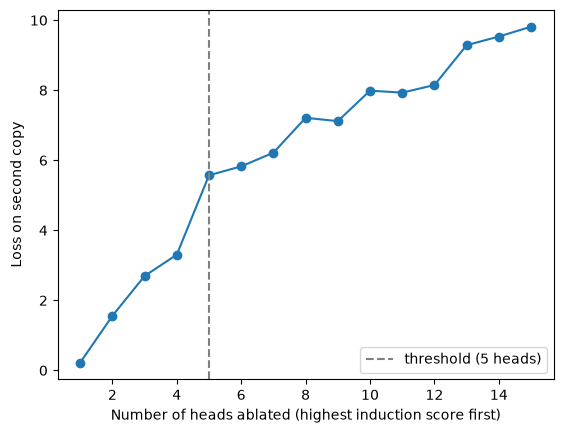

In [52]:
print("Each head alone:")
for head in induction_heads:
    print(head, round(repeated_loss(tokens, make_hooks([head]))[1], 3))

ordered = scores_df.sort_values("induction_score", ascending=False).head(15)
ordered_heads = [(int(r["layer"]), int(r["head"])) for _, r in ordered.iterrows()]

cumulative = []
for k in range(1, len(ordered_heads) + 1):
    cumulative.append(repeated_loss(tokens, make_hooks(ordered_heads[:k]))[1])

plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axvline(len(induction_heads), linestyle="--", color="gray", label=f"threshold ({len(induction_heads)} heads)")
plt.xlabel("Number of heads ablated (highest induction score first)")
plt.ylabel("Loss on second copy")
plt.legend()
plt.show()

No single head accounts for the effect. Ablating each alone raises the loss by at most 0.68 nats (head 5.1), and four of the five by under 0.04, yet ablating all five together adds 5.39. The heads are therefore highly redundant: removing one is largely compensated for by the others. The cumulative curve keeps rising past my 0.8 threshold, to about 9.8 at 15 heads, which suggests lower-scoring heads also contribute and that the threshold is a convenience, not a sharp boundary

So far I’ve shown the effect on copying random tokens. My title asks about in-context learning more broadly, which is a larger claim, so I run two further tests. The first is a key-value lookup task, which is close to induction. The second is Olsson et al.’s in-context learning score on natural text, which is a broader measure.

In [54]:
def lookup_accuracy(n_pairs=10, n_trials=200, fwd_hooks=[]):
    correct = 0
    for _ in range(n_trials):
        ids = torch.randperm(model.cfg.d_vocab - 1000)[: 2 * n_pairs] + 1000
        keys, vals = ids[:n_pairs], ids[n_pairs:]
        j = torch.randint(0, n_pairs, (1,)).item()
        seq = [model.tokenizer.bos_token_id]
        for k, v in zip(keys, vals):
            seq += [k.item(), v.item()]
        seq.append(keys[j].item())
        t = torch.tensor([seq])
        with torch.no_grad():
            logits = model.run_with_hooks(t, fwd_hooks=fwd_hooks)
        correct += (logits[0, -1].argmax().item() == vals[j].item())
    return correct / n_trials

print("Accuracy, normal: ", lookup_accuracy())
print("Accuracy, ablated:", lookup_accuracy(fwd_hooks=make_hooks(induction_heads)))

Accuracy, normal:  0.525
Accuracy, ablated: 0.155


On the key-value lookup task (10 random key-value pairs followed by one repeated key), accuracy fell from 52.5% to 15.5% after ablating the five induction heads (200 trials each; the standard error is about 3 percentage points, so the drop is well outside noise). The ablated accuracy is close to the 10% expected from guessing one of the ten values in the prompt, so the heads appear to supply most of the model's ability to select the correct value. This task is still very close to induction, since the answer is the token that followed the earlier occurrence of the key, so it supports the earlier result without testing anything much broader.

In [55]:
from datasets import load_dataset
ds = load_dataset("NeelNanda/pile-10k", split="train")

docs = []
for ex in ds:
    t = model.to_tokens(ex["text"])
    if t.shape[1] >= 512:
        docs.append(t[0, :512])
    if len(docs) == 50:
        break
docs = torch.stack(docs)

# Means from natural text (first 25 docs), evaluation on the other 25
natural_means = compute_means(docs[:25])
eval_docs = docs[25:]

def icl_score(token_batch, fwd_hooks=[]):
    with torch.no_grad():
        logits = model.run_with_hooks(token_batch, fwd_hooks=fwd_hooks)
    lp = logits.log_softmax(-1)
    loss = -lp[:, :-1].gather(-1, token_batch[:, 1:].unsqueeze(-1)).squeeze(-1)
    return (loss[:, 450:500].mean() - loss[:, 40:50].mean()).item()

print("ICL score, normal: ", icl_score(eval_docs))
print("ICL score, ablated:", icl_score(eval_docs, make_hooks(induction_heads, natural_means)))

README.md:   0%|          | 0.00/373 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/921 [00:00<?, ?B/s]

data/train-00000-of-00001-4746b8785c874c(…): reconstructing file:   0%|          |  0.00B / 33.3MB            

data/train-00000-of-00001-4746b8785c874c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10000 [00:00<?, ? examples/s]

ICL score, normal:  -0.7110257148742676
ICL score, ablated: -0.5042297840118408
